## Лабораторная работа 3. Кластеризация городов методом DBSCAN

**Тема:** экономика городов.

Данные те же, что в первых двух работах. В первой я резал иерархию Уорда на четыре группы, во второй остановился на четырех кластерах k-средних. Оба метода раскладывают каждый город в какую-нибудь группу, а число групп выбираю я. DBSCAN число групп не просит: он ищет, где города лежат плотно, а точки в редких местах может оставить без группы.

## 1. Описание данных

Данные описывают экономические условия в 48 городах мира в 1991 году. Их собрал отдел экономических исследований банка Union (Швейцария).

- **Файл:** `data/Econom_Cities_data.csv` (разделитель `;`, десятичная запятая)
- **Число наблюдений:** 48

| Переменная | Название | Описание |
|---|---|---|
| `City` | Город | Название города |
| `Work` | Работа | Взвешенное среднее числа рабочих часов по 12 профессиям |
| `Price` | Цена | Индекс цен 112 товаров и услуг, включая аренду жилья (для Цюриха взято 100) |
| `Salary` | Заработная плата | Индекс часовой зарплаты по 12 профессиям после налогов и вычетов (для Цюриха взято 100) |

## 2. Постановка задачи

Разбить города по признакам `Work`, `Price` и `Salary` методом DBSCAN. Число групп заранее не задано. Нужно подобрать `eps` и `min_samples`, объяснить выбор, описать получившиеся группы и отдельно разобрать города, которые попали в шум. В конце сравнить результат с четырьмя кластерами из первой и второй работ. Отдельно повторить разбиение по `Work` и `RealWage`, как в тех работах.

## 3. Этапы решения

1. Загрузка и проверка данных.
2. Обработка пропусков.
3. Короткий разведочный анализ.
4. Стандартизация признаков.
5. Как устроен DBSCAN, на искусственных точках.
6. Подбор `min_samples` и `eps`.
7. Итоговое разбиение и разбор шума.
8. Сравнение с лабораторными 1 и 2.
9. Покупательная способность: повтор DBSCAN по `Work` и `RealWage`.
10. Выводы.

## Окружение и библиотеки

In [1]:
import os

os.environ['LOKY_MAX_CPU_COUNT'] = '2'

%matplotlib inline

from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

## Этап 1. Загрузка и проверка данных

Столбцы разделены `;`, дробная часть записана через запятую.

In [2]:
DATA_PATH = Path('../data/Econom_Cities_data.csv')

df = pd.read_csv(DATA_PATH, sep=';', decimal=',')
df.head()

,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5
3,Bombay,2052,30.3,5.3
4,Brussels,1708,73.8,50.5


In [3]:
print('Размер таблицы:', df.shape)
print('Повторяющихся названий городов:', int(df['City'].duplicated().sum()))

df.dtypes

Размер таблицы: (48, 4)
Повторяющихся названий городов: 0


City       object
Work        int64
Price     float64
Salary    float64
dtype: object

## Этап 2. Обработка пропусков

В файле пропуск записан числом `-9999`. Найду такие строки.

In [4]:
numeric_columns = ['Work', 'Price', 'Salary']

missing_rows = df[numeric_columns].eq(-9999).any(axis=1)
df.loc[missing_rows]

,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


У Cairo и Jakarta заполнен только `Price`. Восстанавливать два признака из трех по одному оставшемуся не буду: город встанет рядом с «средним», хотя про работу и зарплату мы ничего не знаем. Эти две строки убираю, как в первых двух работах.

In [5]:
df_clean = df.copy()
df_clean[numeric_columns] = df_clean[numeric_columns].replace(-9999, np.nan)
df_clean = df_clean.dropna(subset=numeric_columns).copy()
df_clean['Work'] = df_clean['Work'].astype(int)
df_clean = df_clean.set_index('City')

print('Было строк:', len(df), 'осталось:', len(df_clean))
df_clean.head()

Было строк: 48 осталось: 46


,Work,Price,Salary
City,,,
Amsterdam,1714,65.6,49.0
Athens,1792,53.8,30.4
Bogota,2152,37.9,11.5
Bombay,2052,30.3,5.3
Brussels,1708,73.8,50.5


### Итог этапа 2

Дальше работаю с 46 городами. Пропусков в `df_clean` нет.

## Этап 3. Разведочный анализ

Подробный разбор был в первой работе. Здесь только то, что нужно для расстояний: масштаб признаков, связь между ними и крайние города.

In [6]:
stats = df_clean[numeric_columns].describe().T
stats['skew'] = df_clean[numeric_columns].skew()
stats.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
Work,46.0,1879.91,174.34,1583.0,1745.25,1849.00,1976.25,2375.0,0.77
Price,46.0,70.10,21.39,30.3,51.78,70.95,81.90,115.5,0.41
Salary,46.0,39.55,24.76,2.7,14.38,43.65,59.70,100.0,0.21


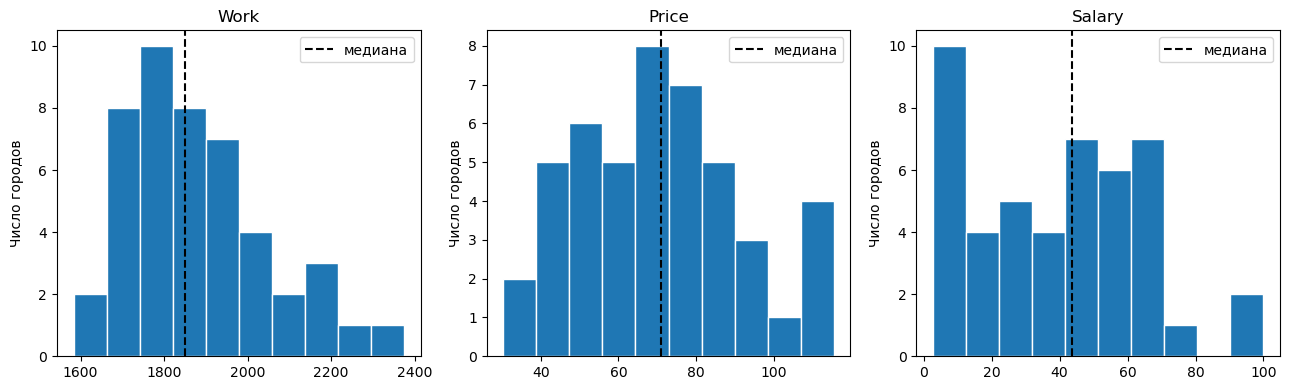

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, column in zip(axes, numeric_columns):
    ax.hist(df_clean[column], bins=10, edgecolor='white')
    ax.axvline(df_clean[column].median(), color='black', linestyle='--', label='медиана')
    ax.set_title(column)
    ax.set_ylabel('Число городов')
    ax.legend()

plt.tight_layout()
plt.show()

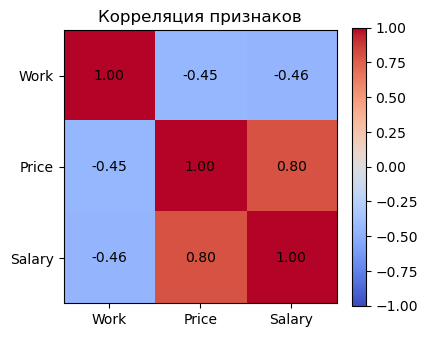

In [8]:
correlation = df_clean[numeric_columns].corr()

fig, ax = plt.subplots(figsize=(4.2, 3.6))
image = ax.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(image, ax=ax, fraction=0.046)
ax.set_xticks(range(3), numeric_columns)
ax.set_yticks(range(3), numeric_columns)

for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{correlation.iloc[i, j]:.2f}', ha='center', va='center')

ax.set_title('Корреляция признаков')
plt.tight_layout()
plt.show()

### Итог этапа 3

`Work` измеряется тысячами часов, `Price` и `Salary` это индексы примерно от 30 до 100. Если считать расстояние по сырым числам, почти весь вклад даст `Work`.

`Price` и `Salary` связаны положительно, корреляция около 0.80: где дороже, там выше индекс зарплаты. С `Work` оба связаны отрицательно, около −0.45.

Самый длинный день у Hong Kong, 2375 часов. Это край распределения, а не сбой в файле, поэтому строку оставляю. Ниже будет видно, оставит ли DBSCAN его без группы.

## Этап 4. Стандартизация признаков

Считаю z-оценки, как в прошлых работах:

$$
z = \frac{x - \bar{x}}{s}.
$$

После этого единица по каждой оси равна одному стандартному отклонению.

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(df_clean[numeric_columns])

df_scaled = pd.DataFrame(X, columns=numeric_columns, index=df_clean.index)
df_scaled.head()

,Work,Price,Salary
City,,,
Amsterdam,-0.962166,-0.212712,0.386095
Athens,-0.509827,-0.770489,-0.373488
Bogota,1.577891,-1.522069,-1.145323
Bombay,0.997969,-1.881316,-1.398517
Brussels,-0.996961,0.174896,0.447351


In [10]:
print('Средние:')
print(df_scaled.mean().round(3))
print()
print('Стандартные отклонения:')
print(df_scaled.std(ddof=0).round(3))

Средние:
Work      0.0
Price    -0.0
Salary    0.0
dtype: float64

Стандартные отклонения:
Work      1.0
Price     1.0
Salary    1.0
dtype: float64


### Итог этапа 4

Средние стали 0, стандартные отклонения 1. Дальше расстояния считаю по матрице `X`.

## Этап 5. Как устроен DBSCAN

Метод смотрит не на центры групп, а на то, где точки лежат кучно. Задаются два числа: радиус `eps` и порог `min_samples`.

Окрестность точки $x$ в стандартизованных координатах:

$$
N_\varepsilon(x) = \{ y : \|z_x - z_y\| \le \varepsilon \}.
$$

Сама точка $x$ в эту окрестность входит, так считает `sklearn`.

- Точка **основная**, если в ее окрестности хотя бы `min_samples` точек.
- Точка **граничная**, если сама она не основная, но попадает в окрестность какой-то основной. Ее забирают в кластер, но продолжать цепочку от нее нельзя.
- Точка **шум**, если она не основная и ни одна основная точка до нее не дотягивается. В группу ее не кладут.

Кластер собирается так: берется основная точка и к ней добавляются все, до кого можно дойти шагами длины не больше `eps`, причем каждый шаг делается из основной точки. Группа может получиться вытянутой. k-средние такую полосу часто режут пополам, потому что ставят два центра. DBSCAN оставит ее целиком, если по дороге плотность не проседает.

Число кластеров из этих правил получается само. Если `eps` маленький, почти все станет шумом. Если `eps` большой, соседние сгустки склеятся.

Посмотрю это на искусственных точках, чтобы не путать картинку с городами. Два пятна и четыре дальние точки. Для плоской картинки беру `min_samples = 4`. У городов три признака, там порог подберу отдельно.

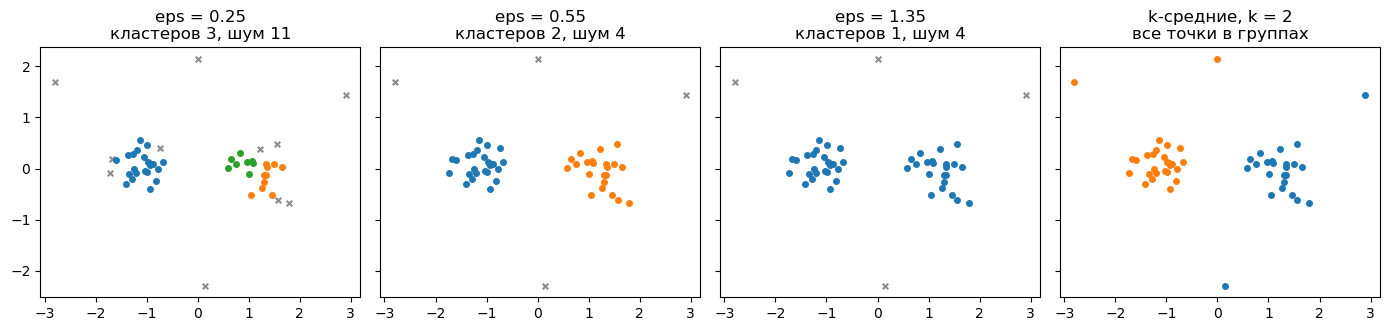

In [11]:
from sklearn.cluster import DBSCAN, KMeans

rng = np.random.default_rng(11)
blob_a = rng.normal(loc=(-1.15, 0.15), scale=0.30, size=(26, 2))
blob_b = rng.normal(loc=(1.15, -0.10), scale=0.32, size=(22, 2))
outliers = np.array([
    [-2.8, 1.7],
    [0.0, 2.15],
    [2.9, 1.45],
    [0.15, -2.3],
])
toy = np.vstack([blob_a, blob_b, outliers])

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharex=True, sharey=True)

for ax, eps in zip(axes[:3], (0.25, 0.55, 1.35)):
    toy_labels = DBSCAN(eps=eps, min_samples=4).fit(toy).labels_
    for label in sorted(set(toy_labels)):
        points = toy[toy_labels == label]
        if label == -1:
            ax.scatter(points[:, 0], points[:, 1], c='0.55', s=16, marker='x')
        else:
            ax.scatter(points[:, 0], points[:, 1], s=16)
    n_clusters = len(set(toy_labels) - {-1})
    n_noise = int((toy_labels == -1).sum())
    ax.set_title(f'eps = {eps}\nкластеров {n_clusters}, шум {n_noise}')
    ax.set_aspect('equal')

kmeans_labels = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(toy)
for label in sorted(set(kmeans_labels)):
    points = toy[kmeans_labels == label]
    axes[3].scatter(points[:, 0], points[:, 1], s=16)
axes[3].set_title('k-средние, k = 2\nвсе точки в группах')
axes[3].set_aspect('equal')

plt.tight_layout()
plt.show()

На первом кадре радиус маленький: одно пятно порвалось на куски, серых крестиков много. На втором два пятна собрались, шумом остались четыре дальние точки. На третьем радиус большой, пятна слиплись, а дальние точки все еще снаружи. На четвертом кадре k-средние с `k = 2` забирают и эти четыре точки: оставить точку без группы этот метод не умеет.

На реальных данных буду искать средний режим. Слишком маленький `eps` оставит шум из десятков городов, слишком большой склеит плотные области в одну.

## Этап 6. Подбор параметров

Признаков три, городов 46. `min_samples = 2` почти повторяет одиночную связь: хватает цепочки пар, и группы слипаются случайно. Слишком большой порог, около 10, на такой выборке тоже плох: у многих городов просто нет десяти соседей рядом. Обычно для `p` признаков смотрят порог от `p + 1` до `2p`, здесь это 4, 5 и 6. В `sklearn` в эти 4–6 входит и сама точка.

Сначала смотрю, как от `eps` меняются число кластеров и число городов в шуме.

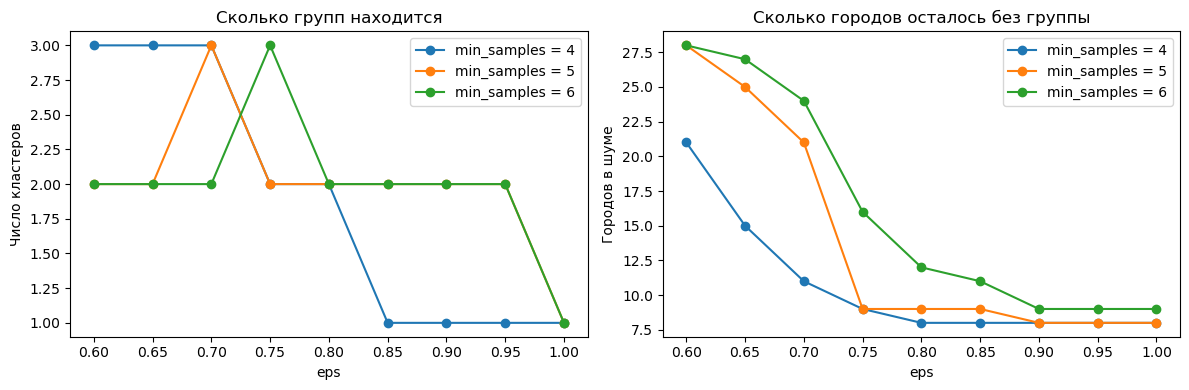

In [12]:
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

eps_values = [0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 1.00]
min_samples_values = [4, 5, 6]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

for min_samples in min_samples_values:
    n_clusters = []
    n_noise = []
    for eps in eps_values:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit(X).labels_
        n_clusters.append(len(set(labels) - {-1}))
        n_noise.append(int((labels == -1).sum()))
    axes[0].plot(eps_values, n_clusters, marker='o', label=f'min_samples = {min_samples}')
    axes[1].plot(eps_values, n_noise, marker='o', label=f'min_samples = {min_samples}')

axes[0].set_ylabel('Число кластеров')
axes[1].set_ylabel('Городов в шуме')
axes[0].set_title('Сколько групп находится')
axes[1].set_title('Сколько городов осталось без группы')

for ax in axes:
    ax.set_xlabel('eps')
    ax.set_xticks(eps_values)
    ax.legend()

plt.tight_layout()
plt.show()

`min_samples = 4` держит два кластера только около 0.75–0.80. На 0.85 остается одна группа: радиус чуть вырос, и цепочка между сгустками уже проходит. Такой порог слишком чувствительный.

`min_samples = 6` два кластера тоже находит, но шума больше. На `eps = 0.80` без группы остаются 12 городов, часть из них это обычный край облака, а не отдельная история.

`min_samples = 5` дает самый спокойный участок: от 0.75 до 0.95 держатся два кластера, в шуме 8 или 9 городов. Беру пятерку. Она между `p + 1 = 4` и `2p = 6`.

У пятерки посмотрю еще силуэт. Считаю его только по городам вне шума и только если кластеров больше одного. В первой и второй работах маленький силуэт значил, что город лежит между группами. Здесь есть ловушка: если выкинуть всех неудобных, силуэт оставшихся легко завысить.

In [13]:
rows = []

for eps in eps_values:
    labels = DBSCAN(eps=eps, min_samples=5).fit(X).labels_
    kept = labels != -1
    n_clusters = len(set(labels[kept]))
    if n_clusters > 1:
        silhouette = silhouette_score(X[kept], labels[kept])
    else:
        silhouette = np.nan
    rows.append({
        'eps': eps,
        'Кластеров': n_clusters,
        'Шум': int((~kept).sum()),
        'В кластерах': int(kept.sum()),
        'Silhouette': silhouette,
    })

pd.DataFrame(rows).set_index('eps').round(3)

,Кластеров,Шум,В кластерах,Silhouette
eps,,,,
0.60,2,28,18,0.726
0.65,2,25,21,0.680
0.70,3,21,25,0.576
0.75,2,9,37,0.523
0.80,2,9,37,0.523
0.85,2,9,37,0.523
0.90,2,8,38,0.512
0.95,2,8,38,0.512
1.00,1,8,38,NaN


На `eps = 0.60` силуэт около 0.73, но в шуме 28 городов из 46. Оценка посчитана по оставшемуся плотному куску, поэтому она мало о чем говорит. На `eps = 0.70` формально три кластера, и снова 21 город в шуме: третья группа здесь обломок, а не устойчивое деление.

От 0.75 до 0.95 силуэт около 0.51–0.52 при двух кластерах. На `eps = 1.00` кластер один, силуэт не считается, деление пропадает.

### Расстояние до 5-го соседа

Точка основная при `min_samples = 5`, когда в шаре радиуса `eps` есть пять точек вместе с ней самой. Это то же самое, что расстояние до 5-го соседа в списке `NearestNeighbors` не больше `eps`. Первый в этом списке сама точка, расстояние до нее нулевое, так что пятый сосед это четвертый *другой* город. Обозначу это расстояние $d_5(x)$.

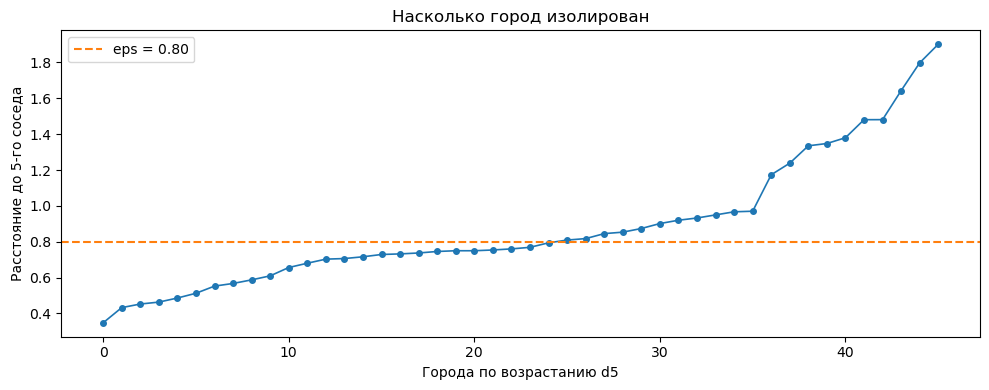

Городов с d5 <= 0.80: 25


,d5
City,
Los_Angeles,1.174
Helsinki,1.238
Manila,1.335
Taipei,1.348
Stockholm,1.380
Tokyo,1.481
Geneva,1.481
Oslo,1.643
Zurich,1.798


In [14]:
kdist = pd.Series(
    NearestNeighbors(n_neighbors=5).fit(X).kneighbors(X)[0][:, -1],
    index=df_clean.index,
    name='d5',
)
sorted_kdist = kdist.sort_values()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(len(sorted_kdist)), sorted_kdist.to_numpy(), marker='o', ms=4, lw=1.2)
ax.axhline(0.80, color='C1', linestyle='--', label='eps = 0.80')
ax.set_xlabel('Города по возрастанию d5')
ax.set_ylabel('Расстояние до 5-го соседа')
ax.set_title('Насколько город изолирован')
ax.legend()
plt.tight_layout()
plt.show()

print('Городов с d5 <= 0.80:', int((kdist <= 0.80).sum()))
sorted_kdist.tail(10).round(3).to_frame('d5')

Кривая долго идет полого и поднимается после Bombay: у него $d_5$ около 0.97, у Los Angeles уже 1.17, дальше Helsinki, Manila, Taipei, Stockholm, Tokyo, Geneva, Oslo, Zurich и Hong Kong. Самый изолированный город это Hong Kong, $d_5$ около 1.90.

Иногда `eps` ставят прямо на этот изгиб. Здесь так делать не стоит: изгиб лежит около 1.2, а уже при `eps = 1` на графике выше остается один кластер. Два плотных облака склеиваются раньше, чем редкие города становятся основными. Проверю, через какую пару они склеиваются.

In [15]:
print(
    'Houston — Tel Aviv:',
    round(float(np.linalg.norm(df_scaled.loc['Houston'] - df_scaled.loc['Tel_Aviv'])), 3),
)
print(
    'Tel Aviv — Singpore:',
    round(float(np.linalg.norm(df_scaled.loc['Tel_Aviv'] - df_scaled.loc['Singpore'])), 3),
)

neighbor_distances, neighbor_index = NearestNeighbors(n_neighbors=5).fit(X).kneighbors(X)
houston_pos = df_clean.index.get_loc('Houston')
print(
    'd5(Houston) =',
    round(float(neighbor_distances[houston_pos, -1]), 3),
    df_clean.index[neighbor_index[houston_pos, -1]],
)

before = DBSCAN(eps=0.95, min_samples=5).fit(X)
after = DBSCAN(eps=0.97, min_samples=5).fit(X)
new_core = set(df_clean.index[after.core_sample_indices_]) - set(df_clean.index[before.core_sample_indices_])
print('Новые основные точки при eps = 0.97:', sorted(new_core))

for eps in (0.95, 0.97):
    labels = DBSCAN(eps=eps, min_samples=5).fit(X).labels_
    n_clusters_eps = len(set(labels) - {-1})
    n_noise_eps = int((labels == -1).sum())
    print(f'eps = {eps}: кластеров {n_clusters_eps}, шум {n_noise_eps}')

Houston — Tel Aviv: 0.845
Tel Aviv — Singpore: 0.491
d5(Houston) = 0.967 Montreal
Новые основные точки при eps = 0.97: ['Houston']
eps = 0.95: кластеров 2, шум 8
eps = 0.97: кластеров 1, шум 8


Houston и Tel Aviv стоят в 0.845 друг от друга. Во второй работе Tel Aviv как раз лежал между «Скромными доходами» и «Длинной сменой», у него был отрицательный силуэт.

При `eps = 0.80` Houston еще не основная точка: его $d_5$ около 0.97, пятый сосед это Montreal. Tel Aviv при этом держится за низкую зарплату, до Singpore всего около 0.49. Как только `eps` доходит до 0.97, Houston становится основным и уже включает Tel Aviv в свой шар. Группы склеиваются в одну. Поэтому `eps` около 1, прямо на изгибе графика $d_5$, для этих данных уже большой: группы к этому моменту слиплись.

Осталось выбрать точку внутри спокойного участка. Сравниваю соседние `eps` с разбиением при 0.80: adjusted Rand равен 1, если города разложены одинаково, включая шум.

In [16]:
base_labels = DBSCAN(eps=0.80, min_samples=5).fit(X).labels_

for eps in (0.75, 0.85, 0.90, 0.95, 0.97):
    labels = DBSCAN(eps=eps, min_samples=5).fit(X).labels_
    rand = adjusted_rand_score(base_labels, labels)
    changed = list(df_clean.index[labels != base_labels])
    n_clusters_eps = len(set(labels) - {-1})
    n_noise_eps = int((labels == -1).sum())
    print(
        f'eps = {eps}: Rand = {rand:.3f}, кластеров {n_clusters_eps}, '
        f'шум {n_noise_eps}, отличия: {changed}'
    )

print()
for eps in (0.75, 0.80, 0.85):
    model_eps = DBSCAN(eps=eps, min_samples=5).fit(X)
    print(
        f'eps = {eps}: основных {len(model_eps.core_sample_indices_)}, '
        f'шум {(model_eps.labels_ == -1).sum()}'
    )

eps = 0.75: Rand = 1.000, кластеров 2, шум 9, отличия: []
eps = 0.85: Rand = 1.000, кластеров 2, шум 9, отличия: []
eps = 0.9: Rand = 0.945, кластеров 2, шум 8, отличия: ['Los_Angeles']
eps = 0.95: Rand = 0.945, кластеров 2, шум 8, отличия: ['Los_Angeles']
eps = 0.97: Rand = 0.336, кластеров 1, шум 8, отличия: ['Athens', 'Bogota', 'Bombay', 'Buenos_Aires', 'Caracas', 'Johannesburg', 'Kuala_Lumpur', 'Lagos', 'Lisbon', 'Los_Angeles', 'Manila', 'Mexico_City', 'Nairobi', 'Nicosia', 'Panama', 'Rio_de_Janeiro', 'San_Paulo', 'Seoul', 'Singpore', 'Tel_Aviv']

eps = 0.75: основных 21, шум 9
eps = 0.8: основных 25, шум 9
eps = 0.85: основных 28, шум 9


От 0.75 до 0.85 состав групп один и тот же, Rand равен 1. Меняется только число основных точек: 21, потом 25, потом 28. На 0.90 и 0.95 из шума выходит один Los Angeles, Rand около 0.95. На 0.97 группы слипаются.

Беру `eps = 0.80`, середину отрезка, где разбиение не двигается. Основных точек уже 25 из 37, кластеры не висят на паре граничных городов, и до склейки через Houston еще есть запас. `min_samples = 5`.

## Этап 7. Итоговое разбиение

Параметры: `eps = 0.80`, `min_samples = 5`.

Номера DBSCAN ни к чему не привязаны, как у k-средних. Нумерую группы по убыванию средней зарплаты, шум оставляю под номером −1. Средние считаю по исходным шкалам.

In [17]:
CHOSEN_EPS = 0.80
CHOSEN_MIN_SAMPLES = 5

model = DBSCAN(eps=CHOSEN_EPS, min_samples=CHOSEN_MIN_SAMPLES).fit(X)
raw_labels = pd.Series(model.labels_, index=df_clean.index)

salary_order = (
    df_clean.loc[raw_labels != -1]
    .groupby(raw_labels)['Salary']
    .mean()
    .sort_values(ascending=False)
    .index
)
label_map = {old: new for new, old in enumerate(salary_order, start=1)}
label_map[-1] = -1

cluster_names = {
    1: 'Высокая зарплата',
    2: 'Низкая зарплата',
    -1: 'Шум',
}

df_clusters = df_clean.copy()
df_clusters['Cluster'] = raw_labels.map(label_map)
df_clusters['Название'] = df_clusters['Cluster'].map(cluster_names)

core_cities = set(df_clean.index[model.core_sample_indices_])

def point_role(city):
    if df_clusters.loc[city, 'Cluster'] == -1:
        return 'шум'
    if city in core_cities:
        return 'основная'
    return 'граничная'

df_clusters['Роль'] = [point_role(city) for city in df_clusters.index]

clustered = df_clusters[df_clusters['Cluster'] != -1]
profile = clustered.groupby('Cluster')[numeric_columns].mean()
profile['Городов'] = clustered['Cluster'].value_counts()
profile['Название'] = profile.index.map(cluster_names)
profile['Salary/Price'] = (
    clustered['Salary'].div(clustered['Price']).groupby(clustered['Cluster']).mean()
)
profile = profile[['Название', 'Work', 'Price', 'Salary', 'Salary/Price', 'Городов']]
profile.round(2)

,Название,Work,Price,Salary,Salary/Price,Городов
Cluster,,,,,,
1,Высокая зарплата,1776.67,77.40,54.60,0.71,18
2,Низкая зарплата,1959.21,50.12,14.79,0.29,19


In [18]:
print(
    f'Кластеров: {df_clusters["Cluster"].max()}, '
    f'шум: {(df_clusters["Cluster"] == -1).sum()}, '
    f'основных точек: {len(core_cities)}'
)
kept_now = (df_clusters['Cluster'] != -1).to_numpy()
print(
    'Силуэт без шума:',
    round(silhouette_score(X[kept_now], df_clusters.loc[kept_now, 'Cluster']), 3),
)

display(df_clusters.groupby(['Название', 'Роль']).size().unstack(fill_value=0))

for cluster in (1, 2, -1):
    cities = df_clusters.index[df_clusters['Cluster'] == cluster]
    print(f'{cluster_names[cluster]} ({len(cities)})')
    print(', '.join(cities))
    print()

Кластеров: 2, шум: 9, основных точек: 25
Силуэт без шума: 0.523


Роль,граничная,основная,шум
Название,,,
Высокая зарплата,3,15,0
Низкая зарплата,9,10,0
Шум,0,0,9


Высокая зарплата (18)
Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Houston, London, Luxembourg, Madrid, Milan, Montreal, New_York, Paris, Sydney, Toronto, Vienna

Низкая зарплата (19)
Athens, Bogota, Bombay, Buenos_Aires, Caracas, Johannesburg, Kuala_Lumpur, Lagos, Lisbon, Manila, Mexico_City, Nairobi, Nicosia, Panama, Rio_de_Janeiro, San_Paulo, Seoul, Singpore, Tel_Aviv

Шум (9)
Geneva, Helsinki, Hong_Kong, Los_Angeles, Oslo, Stockholm, Taipei, Tokyo, Zurich



`Salary/Price` это грубая оценка, сколько индекса зарплаты приходится на единицу индекса цен. Чем число больше, тем выше зарплата относительно местных цен. Так же считал во второй работе.

Плотность оцениваю так же, как во второй работе: средним евклидовым расстоянием от города до центра своей группы. Центр и расстояние считаю по z-оценкам. Шум в эту таблицу не входит: у этих городов общего центра нет.

In [19]:
points = df_scaled.loc[clustered.index, numeric_columns]
centers = points.groupby(df_clusters.loc[clustered.index, 'Cluster']).mean()
assigned = centers.loc[df_clusters.loc[clustered.index, 'Cluster'].to_numpy()].to_numpy()
clustered = clustered.copy()
clustered['До центра'] = np.linalg.norm(points.to_numpy() - assigned, axis=1)

(
    clustered.groupby('Название')['До центра']
    .mean()
    .reindex(['Высокая зарплата', 'Низкая зарплата'])
    .round(3)
    .to_frame('Среднее расстояние до центра')
)

,Среднее расстояние до центра
Название,
Высокая зарплата,0.662
Низкая зарплата,0.940


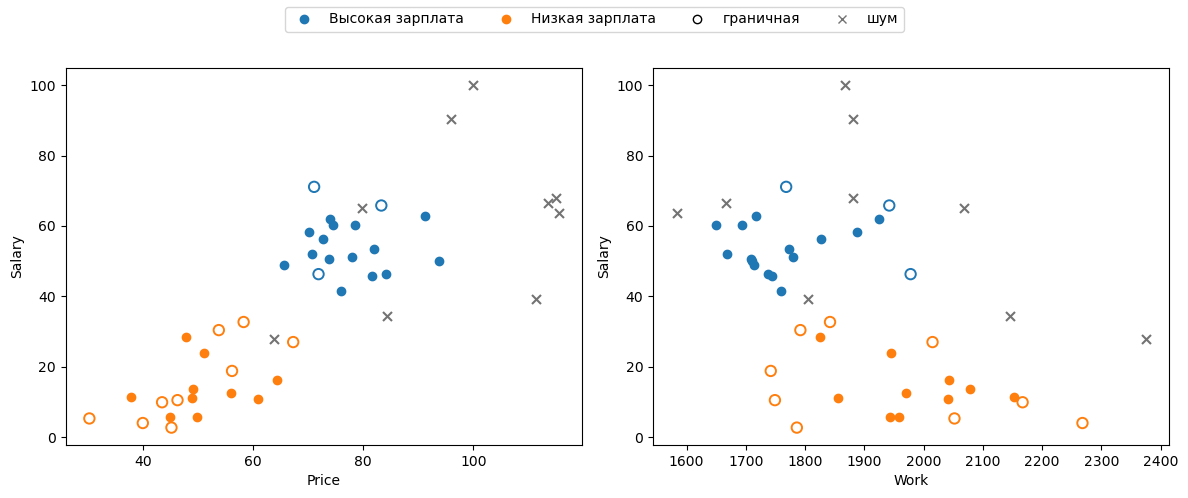

In [20]:
from matplotlib.lines import Line2D

palette = {1: 'C0', 2: 'C1'}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (x_column, y_column) in zip(axes, (('Price', 'Salary'), ('Work', 'Salary'))):
    for cluster in (1, 2):
        group = df_clusters[df_clusters['Cluster'] == cluster]
        core = group[group['Роль'] == 'основная']
        border = group[group['Роль'] == 'граничная']
        ax.scatter(core[x_column], core[y_column], c=palette[cluster], s=36)
        ax.scatter(
            border[x_column], border[y_column],
            facecolors='none', edgecolors=palette[cluster], s=56, linewidths=1.4,
        )
    noise = df_clusters[df_clusters['Cluster'] == -1]
    ax.scatter(noise[x_column], noise[y_column], c='0.45', marker='x', s=42)
    ax.set_xlabel(x_column)
    ax.set_ylabel(y_column)

legend_handles = [
    Line2D([0], [0], marker='o', color='C0', linestyle='None', label='Высокая зарплата'),
    Line2D([0], [0], marker='o', color='C1', linestyle='None', label='Низкая зарплата'),
    Line2D([0], [0], marker='o', markerfacecolor='none', markeredgecolor='black', linestyle='None', label='граничная'),
    Line2D([0], [0], marker='x', color='0.45', linestyle='None', label='шум'),
]
fig.legend(handles=legend_handles, loc='upper center', ncol=4)
fig.tight_layout(rect=(0, 0, 1, 0.90))
plt.show()

Залитые точки основные, пустые кружки граничные, крестики шум. Подпишу шум на 3D-графике, его можно повернуть. Houston и Tel Aviv тоже подпишу: через эту пару группы слипаются, если увеличить `eps` до 0.97.

In [21]:
import plotly.express as px

plot_df = df_clusters.reset_index()
signed_cities = set(df_clusters.index[df_clusters['Cluster'] == -1]) | {'Houston', 'Tel_Aviv'}
plot_df['Подпись'] = plot_df['City'].where(plot_df['City'].isin(signed_cities), '')
plot_df['Подпись'] = plot_df['Подпись'].str.replace('_', ' ', regex=False)

name_order = ['Высокая зарплата', 'Низкая зарплата', 'Шум']
fig_3d = px.scatter_3d(
    plot_df,
    x='Work',
    y='Price',
    z='Salary',
    color='Название',
    symbol='Роль',
    hover_name='City',
    text='Подпись',
    category_orders={'Название': name_order, 'Роль': ['основная', 'граничная', 'шум']},
    color_discrete_map={
        'Высокая зарплата': '#4c78a8',
        'Низкая зарплата': '#f58518',
        'Шум': '#9a9a9a',
    },
    title='DBSCAN, eps = 0.80, min_samples = 5',
    height=650,
)
fig_3d.update_traces(marker_size=5, textposition='top center', textfont_size=11)
fig_3d.show()

### Описание групп

1. **Высокая зарплата**, 18 городов. Средние примерно такие: `Work` 1777, `Price` 77.4, `Salary` 54.6, `Salary/Price` около 0.71. Среднее расстояние до центра около 0.66, это плотная группа. Основных точек 15. На краю остаются Houston, Luxembourg и New York: соседей в радиусе 0.80 у них меньше пяти, но до основной точки они дотягиваются. По составу это почти «Богачи» из второй работы, без Los Angeles. Его разберу вместе с шумом.

2. **Низкая зарплата**, 19 городов. `Salary` около 14.8, `Price` около 50.1, `Salary/Price` около 0.29, `Work` в среднем 1959. Среднее расстояние до центра около 0.94, группа рыхлее первой. Основных точек 10, граничных 9: Athens, Bombay, Kuala Lumpur, Lagos, Lisbon, Manila, Rio de Janeiro, Seoul и Tel Aviv. Разброс по часам большой, от Lisbon с 1742 до Manila с 2268. k-средние во второй работе резали эту полосу на «Скромные доходы» и «Длинную смену». По плотности разрыва нет: Manila граничная, но до основной точки Bogota около 0.75, а между коротким и длинным днем лежат Buenos Aires, Johannesburg, Singpore, Caracas. Цепочка не рвется. Hong Kong и Taipei до нее не дотягиваются.

### Города в шуме

Шум здесь не ошибка записи. Это города, у которых в шаре радиуса 0.80 меньше пяти соседей и которые не попали в шар ни одной основной точки. Посмотрю, в какую сторону каждый из них отстоит от среднего по 46 городам.

In [22]:
noise_order = kdist.loc[df_clusters['Cluster'] == -1].sort_values(ascending=False).index

pairs = [
    ('Geneva', 'Zurich'),
    ('Hong_Kong', 'Manila'),
    ('Los_Angeles', 'Chicago'),
    ('Los_Angeles', 'New_York'),
]
for left, right in pairs:
    distance = np.linalg.norm(df_scaled.loc[left] - df_scaled.loc[right])
    print(f'{left} — {right}: {distance:.3f}')

print('Минимум Work:', df_clean['Work'].idxmin(), int(df_clean['Work'].min()))
print('Максимум Work:', df_clean['Work'].idxmax(), int(df_clean['Work'].max()))
print('Максимум Price:', df_clean['Price'].idxmax(), float(df_clean['Price'].max()))
print('Максимум Salary:', df_clean['Salary'].idxmax(), float(df_clean['Salary'].max()))

noise_table = df_clean.loc[noise_order, numeric_columns].join(
    df_scaled.loc[noise_order].add_suffix(', z')
)
noise_table['d5'] = kdist.loc[noise_order]
noise_table.round(2)

Geneva — Zurich: 0.446
Hong_Kong — Manila: 1.611
Los_Angeles — Chicago: 0.891
Los_Angeles — New_York: 0.750
Минимум Work: Oslo 1583
Максимум Work: Hong_Kong 2375
Максимум Price: Oslo 115.5
Максимум Salary: Zurich 100.0


,Work,Price,Salary,"Work, z","Price, z","Salary, z",d5
City,,,,,,,
Hong_Kong,2375,63.8,27.8,2.87,-0.30,-0.48,1.90
Zurich,1868,100.0,100.0,-0.07,1.41,2.47,1.80
Oslo,1583,115.5,63.7,-1.72,2.15,0.99,1.64
Geneva,1880,95.9,90.3,0.00,1.22,2.07,1.48
Tokyo,1880,115.0,68.0,0.00,2.12,1.16,1.48
Stockholm,1805,111.3,39.2,-0.43,1.95,-0.01,1.38
Taipei,2145,84.3,34.5,1.54,0.67,-0.21,1.35
Helsinki,1667,113.6,66.6,-1.23,2.06,1.10,1.24
Los_Angeles,2068,79.8,65.2,1.09,0.46,1.05,1.17


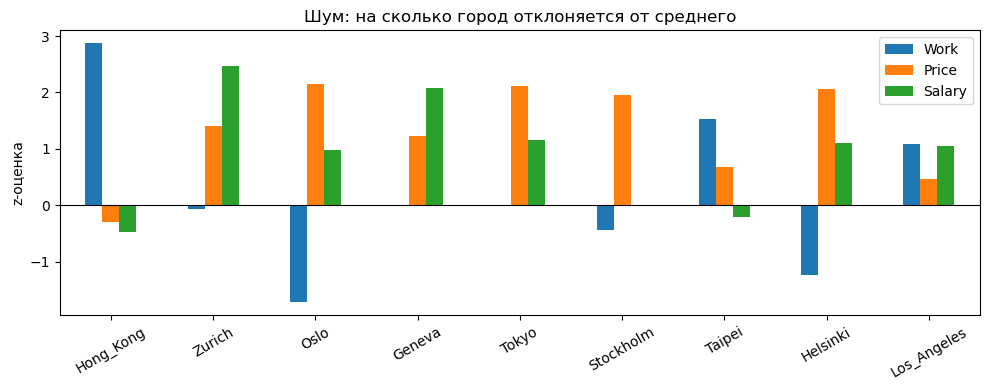

In [23]:
fig, ax = plt.subplots(figsize=(10, 4))
z_noise = df_scaled.loc[noise_order]
z_noise.plot.bar(ax=ax, rot=30)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('z-оценка')
ax.set_xlabel('')
ax.set_title('Шум: на сколько город отклоняется от среднего')
plt.tight_layout()
plt.show()

Три разные причины, одно среднее по этим девяти городам было бы бессмысленным.

**Дорогие города, которые не собрались в шар.** Geneva, Zurich, Oslo, Helsinki, Tokyo, Stockholm. `Price` у них от 95.9 до 115.5, это больше одного стандартного отклонения выше среднего, а у Oslo, Tokyo и Helsinki больше двух. При этом они крайние в разные стороны. У Zurich зарплата 100, у Geneva 90.3. У Stockholm зарплата 39.2 при цене 111.3, отношение `Salary/Price` около 0.35, ближе к бедной половине, чем к Zurich. У Oslo самый короткий день в таблице, 1583 часа, и самая высокая цена, 115.5. Geneva и Zurich близки, расстояние около 0.45, но это пара, а не пять соседей. Своего плотного ядра у шестерки нет, поэтому DBSCAN не делает из них кластер. k-средние в прошлых работах клали их вместе, потому что обязаны были к кому-то отнести.

**Длинный день, который оторвался от низкой зарплаты.** Hong Kong, 2375 часов, z-оценка `Work` около 2.87, $d_5$ около 1.90. Ближайший к нему Manila уже на расстоянии около 1.61. Manila еще граничная точка низкой зарплаты, Hong Kong на шаг дальше. Taipei, 2145 часов, но `Price` 84.3 и `Salary` 34.5. Для группы с низкой зарплатой цена высоковата, для высокой зарплаты низковата зарплата. Во второй работе при пяти кластерах Taipei тоже оказывался лишним в компании Chicago и New York.

**Чуть не дотянулся.** Los Angeles: `Work` 2068 и `Salary` 65.2, длинный день при высокой зарплате. До New York около 0.75, только New York сам граничный, от него цепочку продолжать нельзя. Ближайшая основная точка это Chicago, расстояние около 0.89. При `eps = 0.80` Los Angeles остается шумом. На проверке выше он как раз один менял группу при `eps = 0.90`.

## Этап 8. Сравнение с лабораторными 1 и 2

Повторю два разбиения на тех же z-оценках.

k-средние: `k = 4`, `init = 'k-means++'`, `n_init = 50`, `random_state = 0`, как во второй работе. Имена те же: «Элитки», «Богачи», «Скромные доходы», «Длинная смена».

Иерархия Уорда, разрез на 4 кластера, как в первой: «Элитки», «Богачи», «Бюджетные города», «Работяги». Номера снова ставлю по убыванию средней зарплаты, чтобы таблицы читались одинаково.

In [24]:
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import pdist

kmeans_raw = pd.Series(
    KMeans(n_clusters=4, init='k-means++', n_init=50, random_state=0).fit(X).labels_,
    index=df_clean.index,
)
kmeans_order = df_clean.groupby(kmeans_raw)['Salary'].mean().sort_values(ascending=False).index
kmeans_labels = kmeans_raw.map({old: new for new, old in enumerate(kmeans_order, start=1)})
kmeans_names = {
    1: 'Элитки',
    2: 'Богачи',
    3: 'Скромные доходы',
    4: 'Длинная смена',
}

ward_raw = pd.Series(
    fcluster(linkage(pdist(df_scaled), method='ward'), t=4, criterion='maxclust'),
    index=df_clean.index,
)
ward_order = df_clean.groupby(ward_raw)['Salary'].mean().sort_values(ascending=False).index
ward_labels = ward_raw.map({old: new for new, old in enumerate(ward_order, start=1)})
ward_names = {
    1: 'Элитки (ЛР1)',
    2: 'Богачи (ЛР1)',
    3: 'Бюджетные (ЛР1)',
    4: 'Работяги (ЛР1)',
}

db_order = ['Высокая зарплата', 'Низкая зарплата', 'Шум']
kmeans_order_names = ['Элитки', 'Богачи', 'Скромные доходы', 'Длинная смена']
ward_order_names = ['Элитки (ЛР1)', 'Богачи (ЛР1)', 'Бюджетные (ЛР1)', 'Работяги (ЛР1)']

kmeans_table = pd.crosstab(
    df_clusters['Название'],
    kmeans_labels.map(kmeans_names),
    rownames=['DBSCAN'],
    colnames=['k-средние, k = 4'],
).reindex(index=db_order, columns=kmeans_order_names)
ward_table = pd.crosstab(
    df_clusters['Название'],
    ward_labels.map(ward_names),
    rownames=['DBSCAN'],
    colnames=['Уорд, k = 4'],
).reindex(index=db_order, columns=ward_order_names)

display(kmeans_table)
ward_table

"k-средние, k = 4",Элитки,Богачи,Скромные доходы,Длинная смена
DBSCAN,,,,
Высокая зарплата,0,18,0,0
Низкая зарплата,0,0,11,8
Шум,6,1,0,2


"Уорд, k = 4",Элитки (ЛР1),Богачи (ЛР1),Бюджетные (ЛР1),Работяги (ЛР1)
DBSCAN,,,,
Высокая зарплата,0,18,0,0
Низкая зарплата,0,0,7,12
Шум,6,1,0,2


In [25]:
moved_in_lab2 = ['Buenos_Aires', 'Johannesburg', 'Mexico_City', 'Nairobi']
df_clusters.loc[moved_in_lab2, ['Название', 'Роль', 'Work', 'Price', 'Salary']].sort_values('Work')

,Название,Роль,Work,Price,Salary
City,,,,,
Mexico_City,Низкая зарплата,основная,1944,49.8,5.7
Johannesburg,Низкая зарплата,основная,1945,51.1,24.0
Nairobi,Низкая зарплата,основная,1958,45.0,5.8
Buenos_Aires,Низкая зарплата,основная,1971,56.1,12.5


Во второй работе эти четыре города переехали из «Работяг» Уорда в «Скромные доходы» k-средних: по часам они лежат между двумя нижними центрами. В DBSCAN все четыре попали в «Низкую зарплату», и все четыре там основные точки. По плотности промежутка между коротким и длинным днем нет.

In [26]:
kept = (df_clusters['Cluster'] != -1).to_numpy()
kmeans_two = KMeans(n_clusters=2, n_init=50, random_state=0).fit_predict(X)
ward_two = fcluster(linkage(pdist(df_scaled), method='ward'), t=2, criterion='maxclust')

def safe_silhouette(data, labels):
    labels = np.asarray(labels)
    if len(set(labels)) < 2:
        return np.nan
    return silhouette_score(data, labels)

comparison = pd.DataFrame({
    'Городов': [
        int(kept.sum()),
        len(df_clean),
        int(kept.sum()),
        len(df_clean),
        len(df_clean),
        int(kept.sum()),
    ],
    'Silhouette': [
        safe_silhouette(X[kept], df_clusters.loc[kept, 'Cluster']),
        safe_silhouette(X, kmeans_two),
        safe_silhouette(X[kept], kmeans_two[kept]),
        safe_silhouette(X, kmeans_labels),
        safe_silhouette(X, ward_labels),
        safe_silhouette(X[kept], ward_two[kept]),
    ],
}, index=[
    'DBSCAN, без шума',
    'k-средние, k = 2, все 46',
    'k-средние, k = 2, те же 37',
    'k-средние, k = 4, все 46',
    'Уорд, k = 4, все 46',
    'Уорд, k = 2, те же 37',
])

print(
    'Rand DBSCAN и k-средних k=2 на городах без шума:',
    round(adjusted_rand_score(df_clusters.loc[kept, 'Cluster'], kmeans_two[kept]), 3),
)
print(
    'Rand DBSCAN и Уорда k=2 на городах без шума:',
    round(adjusted_rand_score(df_clusters.loc[kept, 'Cluster'], ward_two[kept]), 3),
)
comparison.round(3)

Rand DBSCAN и k-средних k=2 на городах без шума: 1.0
Rand DBSCAN и Уорда k=2 на городах без шума: 1.0


,Городов,Silhouette
"DBSCAN, без шума",37,0.523
"k-средние, k = 2, все 46",46,0.470
"k-средние, k = 2, те же 37",37,0.523
"k-средние, k = 4, все 46",46,0.366
"Уорд, k = 4, все 46",46,0.355
"Уорд, k = 2, те же 37",37,0.523


Силуэт DBSCAN 0.523 выше, чем 0.366 у четырех кластеров k-средних и 0.470 у двух кластеров на всех 46 городах. Сравнивать так нечестно: DBSCAN посчитал метрику по 37 городам, без девяти трудных.

На этих же 37 городах k-средние и Уорд при двух кластерах дают тот же силуэт, 0.523, и Rand с DBSCAN равен 1. Разбиения совпали. Выигрыш DBSCAN по силуэту целиком объясняется тем, что шум не вошел в расчет.

Четыре группы из первых работ плотностью не разделены. «Элитки» целиком оказались шумом. «Скромные доходы» и «Длинная смена» склеились в одну область, из нее выпали только Hong Kong и Taipei. «Богачи» совпали с «Высокой зарплатой», кроме Los Angeles.

## Этап 9. Покупательная способность

`Price` и `Salary` связаны, корреляция около 0.80, поэтому в расстоянии основного прогона они во многом повторяют друг друга. В первой и второй работах я заменял их одним признаком

$$
RealWage = \frac{Salary}{Price} \cdot 100.
$$

Это покупательная способность: сколько индекса зарплаты приходится на 100 единиц индекса цен. Столбец `Salary/Price` выше это то же отношение, только без умножения на 100. Здесь множитель оставляю, чтобы числа читались так же, как в прошлых работах.

Дальше DBSCAN запускаю заново, уже по двум признакам: `Work` и `RealWage`. Радиус 0.80 и `min_samples = 5` подбирались в трехмерном пространстве. На новой плоскости их переносить нельзя.

In [27]:
df_real = df_clean.copy()
df_real['RealWage'] = df_real['Salary'] / df_real['Price'] * 100

display(df_real['RealWage'].sort_values(ascending=False).head().round(1).to_frame('Самые высокие'))
df_real['RealWage'].sort_values().head().round(1).to_frame('Самые низкие')

,Самые высокие
City,
Zurich,100.0
Luxembourg,100.0
Geneva,94.2
Chicago,83.8
Toronto,82.9


,Самые низкие
City,
Lagos,6.0
Manila,10.0
Mexico_City,11.4
Nairobi,12.9
Bombay,17.5


In [28]:
X_real = StandardScaler().fit_transform(df_real[['Work', 'RealWage']])

old_real = DBSCAN(eps=0.80, min_samples=5).fit(X_real)
print(
    'Старые параметры на плоскости Work–RealWage: кластеров',
    len(set(old_real.labels_) - {-1}),
    ', шум',
    int((old_real.labels_ == -1).sum()),
)

Старые параметры на плоскости Work–RealWage: кластеров 1 , шум 1


Признаков теперь два, поэтому порог соседей смотрю от `p + 1 = 3` до `2p = 4`. Сетка по `eps` короче, чем в основном прогоне: расстояния здесь в среднем меньше.

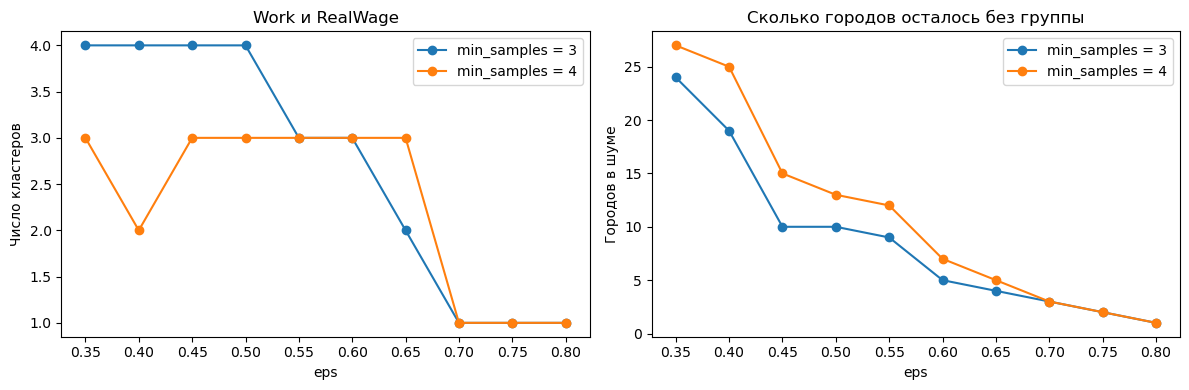

In [29]:
real_eps = [0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

for min_samples in (3, 4):
    cluster_counts = []
    noise_counts = []
    for eps in real_eps:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit(X_real).labels_
        cluster_counts.append(len(set(labels) - {-1}))
        noise_counts.append(int((labels == -1).sum()))
    axes[0].plot(real_eps, cluster_counts, marker='o', label=f'min_samples = {min_samples}')
    axes[1].plot(real_eps, noise_counts, marker='o', label=f'min_samples = {min_samples}')

axes[0].set_ylabel('Число кластеров')
axes[1].set_ylabel('Городов в шуме')
axes[0].set_title('Work и RealWage')
axes[1].set_title('Сколько городов осталось без группы')

for ax in axes:
    ax.set_xlabel('eps')
    ax.set_xticks(real_eps)
    ax.legend()

plt.tight_layout()
plt.show()

In [30]:
rows = []
for eps in real_eps:
    labels = DBSCAN(eps=eps, min_samples=4).fit(X_real).labels_
    kept = labels != -1
    n_clusters = len(set(labels[kept]))
    if n_clusters > 1:
        silhouette = silhouette_score(X_real[kept], labels[kept])
    else:
        silhouette = np.nan
    rows.append({
        'eps': eps,
        'Кластеров': n_clusters,
        'Шум': int((~kept).sum()),
        'Silhouette': silhouette,
    })

display(pd.DataFrame(rows).set_index('eps').round(3))

labels_three = pd.Series(
    DBSCAN(eps=0.50, min_samples=3).fit(X_real).labels_,
    index=df_real.index,
)
sizes = labels_three[labels_three != -1].value_counts()
smallest = sizes.idxmin()
print(
    'min_samples = 3, eps = 0.50, самый маленький кластер:',
    ', '.join(df_real.index[labels_three == smallest]),
    f'({int(sizes.min())} города)',
)

,Кластеров,Шум,Silhouette
eps,,,
0.35,3,27,0.591
0.40,2,25,0.757
0.45,3,15,0.565
0.50,3,13,0.574
0.55,3,12,0.566
0.60,3,7,0.457
0.65,3,5,0.423
0.70,1,3,NaN
0.75,1,2,NaN


min_samples = 3, eps = 0.50, самый маленький кластер: Lisbon, Rio_de_Janeiro, Stockholm (3 города)


При `min_samples = 3` и `eps = 0.50` самый маленький кластер состоит ровно из трех городов: Stockholm, Lisbon и Rio de Janeiro. Это нижняя граница порога, группа держится только потому, что тройка уже считается ядром. Беру `min_samples = 4`, удвоенное число признаков. Тогда эта тройка ядром стать не может.

При четверке на `eps = 0.40` силуэт 0.76, но в шуме 25 городов: в расчет попадают только самые плотные куски. Число кластеров равно 3 от 0.45 до 0.65, состав при этом меняется. До 0.55 отдельно держится группа высокой способности. На 0.60 она сливается со средней, вместо нее появляется четверка Stockholm, Lisbon, San_Paulo и Rio, а силуэт падает до 0.46. Беру `eps = 0.50`. На 0.45 Zurich и Mexico City еще в шуме. На 0.55 Montreal уходит из высокой способности в среднюю, а Oslo выходит из шума. На 0.50 Zurich уже вместе с Geneva, длинный день собран из 10 городов, Montreal еще не перескочил.

In [31]:
REAL_EPS = 0.50
REAL_MIN_SAMPLES = 4

real_model = DBSCAN(eps=REAL_EPS, min_samples=REAL_MIN_SAMPLES).fit(X_real)
raw_real = pd.Series(real_model.labels_, index=df_real.index)
real_order = (
    df_real.loc[raw_real != -1]
    .groupby(raw_real)['RealWage']
    .mean()
    .sort_values(ascending=False)
    .index
)
real_map = {old: new for new, old in enumerate(real_order, start=1)}
real_map[-1] = -1
real_names = {
    1: 'Высокая способность',
    2: 'Средняя способность',
    3: 'Длинный день',
    -1: 'Шум',
}

df_real['Cluster_real'] = raw_real.map(real_map)
df_real['RealWage_кластер'] = df_real['Cluster_real'].map(real_names)

real_kept = df_real[df_real['Cluster_real'] != -1]
real_profile = real_kept.groupby('Cluster_real')[['Work', 'RealWage']].mean()
real_profile['Городов'] = real_kept['Cluster_real'].value_counts()
real_profile.insert(0, 'Название', real_profile.index.map(real_names))
display(real_profile.round(1))

scaled_real = pd.DataFrame(X_real, index=df_real.index, columns=['Work', 'RealWage'])
print(
    'Luxembourg — Zurich:',
    round(float(np.linalg.norm(scaled_real.loc['Luxembourg'] - scaled_real.loc['Zurich'])), 3),
)

for cluster in (1, 2, 3, -1):
    cities = df_real.index[df_real['Cluster_real'] == cluster]
    print(f'{real_names[cluster]} ({len(cities)})')
    print(', '.join(cities))
    print()

,Название,Work,RealWage,Городов
Cluster_real,,,,
1,Высокая способность,1888.2,86.2,6
2,Средняя способность,1744.6,63.7,17
3,Длинный день,2055.0,22.9,10


Luxembourg — Zurich: 0.58
Высокая способность (6)
Chicago, Geneva, Montreal, New_York, Toronto, Zurich

Средняя способность (17)
Amsterdam, Athens, Brussels, Copenhagen, Dublin, Dusseldorf, Frankfurt, Helsinki, London, Madrid, Milan, Nicosia, Paris, Seoul, Sydney, Tokyo, Vienna

Длинный день (10)
Bogota, Bombay, Buenos_Aires, Caracas, Kuala_Lumpur, Mexico_City, Nairobi, Panama, Singpore, Taipei

Шум (13)
Hong_Kong, Houston, Johannesburg, Lagos, Lisbon, Los_Angeles, Luxembourg, Manila, Oslo, Rio_de_Janeiro, San_Paulo, Stockholm, Tel_Aviv



In [32]:
kmeans_real_raw = pd.Series(
    KMeans(n_clusters=4, init='k-means++', n_init=50, random_state=0).fit(X_real).labels_,
    index=df_real.index,
)
kmeans_real_order = (
    df_real.groupby(kmeans_real_raw)['RealWage'].mean().sort_values(ascending=False).index
)
kmeans_real = kmeans_real_raw.map({old: new for new, old in enumerate(kmeans_real_order, start=1)})
kmeans_real_names = {
    1: 'Высокая способность',
    2: 'Средняя способность',
    3: 'Длинный день',
    4: 'Низкая способность',
}

db_order = ['Высокая способность', 'Средняя способность', 'Длинный день', 'Шум']
kmeans_order = ['Высокая способность', 'Средняя способность', 'Длинный день', 'Низкая способность']
main_order = ['Высокая зарплата', 'Низкая зарплата', 'Шум']

kmeans_table = pd.crosstab(
    df_real['RealWage_кластер'],
    kmeans_real.map(kmeans_real_names),
    rownames=['DBSCAN'],
    colnames=['k-средние, ЛР2'],
).reindex(index=db_order, columns=kmeans_order)

main_table = pd.crosstab(
    df_clusters['Название'],
    df_real['RealWage_кластер'],
    rownames=['DBSCAN по трем признакам'],
    colnames=['DBSCAN по RealWage'],
).reindex(index=main_order, columns=db_order)

display(kmeans_table)
main_table

"k-средние, ЛР2",Высокая способность,Средняя способность,Длинный день,Низкая способность
DBSCAN,,,,
Высокая способность,6,0,0,0
Средняя способность,0,17,0,0
Длинный день,0,0,7,3
Шум,3,1,3,6


DBSCAN по RealWage,Высокая способность,Средняя способность,Длинный день,Шум
DBSCAN по трем признакам,,,,
Высокая зарплата,4,12,0,2
Низкая зарплата,0,3,9,7
Шум,2,2,1,4


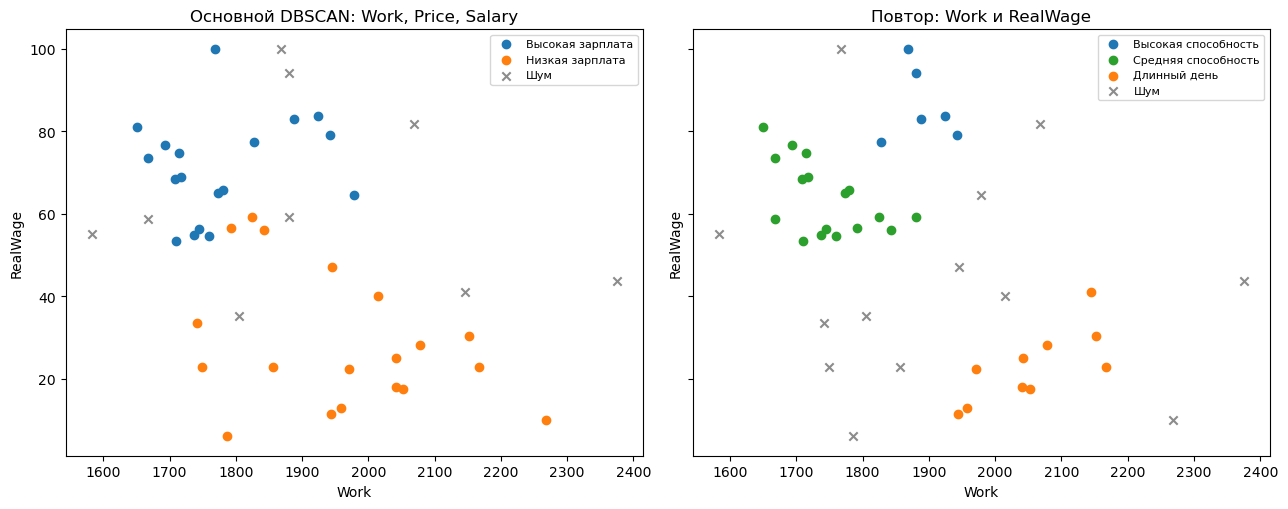

In [33]:
df_clusters = df_clusters.copy()
df_clusters['RealWage'] = df_real['RealWage']

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharex=True, sharey=True)

left_colors = {
    'Высокая зарплата': 'C0',
    'Низкая зарплата': 'C1',
    'Шум': '0.55',
}
for name, color in left_colors.items():
    group = df_clusters[df_clusters['Название'] == name]
    marker = 'x' if name == 'Шум' else 'o'
    axes[0].scatter(group['Work'], group['RealWage'], c=color, marker=marker, s=36, label=name)

right_colors = {
    'Высокая способность': 'C0',
    'Средняя способность': 'C2',
    'Длинный день': 'C1',
    'Шум': '0.55',
}
for name, color in right_colors.items():
    group = df_real[df_real['RealWage_кластер'] == name]
    marker = 'x' if name == 'Шум' else 'o'
    axes[1].scatter(group['Work'], group['RealWage'], c=color, marker=marker, s=36, label=name)

axes[0].set_title('Основной DBSCAN: Work, Price, Salary')
axes[1].set_title('Повтор: Work и RealWage')

for ax in axes:
    ax.set_xlabel('Work')
    ax.set_ylabel('RealWage')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

Слева то же разбиение, что в этапе 7, только оси другие: по вертикали способность, а не зарплата. Справа новый прогон. Имена справа про способность, потому что цена и зарплата по отдельности в расстояние уже не входят.

1. **Высокая способность**, 6 городов: Zurich, Geneva, Chicago, Toronto, New York, Montreal. Средний `RealWage` около 86, `Work` около 1888. Во второй работе k-средние на этих же осях давали 9 городов. Не вошли Luxembourg, Los Angeles и Houston. У Luxembourg способность 100, как у Zurich, но до Zurich на этой плоскости 0.58, а `eps` равен 0.50. Los Angeles и Houston выпадают из-за длинного дня при еще высокой способности.

2. **Средняя способность**, 17 городов, `RealWage` около 64, рабочий день короче, около 1745 часов. Из шума основного прогона сюда попадают Helsinki и Tokyo: цены у них из самых высоких, а способность обычная для богатых городов, около 59. Athens, Nicosia и Seoul в основном прогоне были в низкой зарплате, а здесь в средней: индекс зарплаты низкий, но и цены низкие, отношение ближе к европейской середине, чем к Lagos.

3. **Длинный день**, 10 городов: `Work` около 2055, `RealWage` около 23. Это плотное ядро низкой способности при длинном дне. По сравнению с «Длинной сменой» второй работы края другие. Hong Kong, Manila и Tel Aviv остаются шумом, на этой плоскости они слишком далеко. Buenos Aires, Mexico City и Nairobi входят в группу: способность низкая, и соседей в радиусе 0.50 хватает.

4. **Шум**, 13 городов. Кроме Luxembourg, Los Angeles, Houston, Hong Kong и Manila здесь Oslo, Stockholm, Johannesburg, Tel Aviv, Lisbon, San_Paulo, Rio de Janeiro и Lagos. Oslo при способности 55 изолирован самым коротким днем в таблице, 1583 часа. Stockholm, Lisbon и Rio de Janeiro это как раз та тройка, которой при `min_samples = 3` хватало на отдельный кластер. При четырех соседях не хватает.

С основным разбиением составы не совпадают, и это ожидаемо. Высокая зарплата по трем признакам здесь делится на высокую и среднюю способность. Шесть «Элиток» тоже расходятся: Zurich и Geneva в высокой, Helsinki и Tokyo в средней, Oslo и Stockholm в шуме, Taipei уходит в длинный день. Пока цена и зарплата входят в расстояние по отдельности, дорогие города держатся рядом. Когда остается только способность, это соседство пропадает. Тот же вывод был во второй работе на k-средних.

## Этап 10. Выводы

Города сравнивал по `Work`, `Price` и `Salary` после z-стандартизации. Cairo и Jakarta в расчет не входили: у них известна только цена.

DBSCAN число кластеров заранее не задает. Я взял `min_samples = 5` и `eps = 0.80`. Пятерка лежит между 4 и 6, то есть между числом признаков плюс один и удвоенным числом признаков. При 4 группы слипаются уже на `eps = 0.85`, при 6 в шуме на том же радиусе 12 городов. `eps = 0.80` стоит посередине отрезка 0.75–0.85, где состав групп не меняется. На 0.90 к высокой зарплате добавляется только Los Angeles. Около 0.97 Houston становится основной точкой и через Tel Aviv склеивает обе группы. Изгиб графика $d_5$ лежит еще правее, около 1.2, и на этом радиусе две группы уже одна.

Получились две плотные группы и 9 городов шума.

1. **Высокая зарплата** (18). «Богачи» из второй работы без Los Angeles. `Work` около 1777, `Price` 77.4, `Salary` 54.6, `Salary/Price` около 0.71. Группа плотная, среднее расстояние до центра около 0.66.
2. **Низкая зарплата** (19). «Скромные доходы» и «Длинная смена» вместе, без Hong Kong и Taipei. Зарплата около 14.8, часы в среднем 1959, но внутри есть и короткий день, и длинный. По плотности они связаны через промежуточные города, поэтому DBSCAN их не режет. Среднее расстояние до центра около 0.94.
3. **Шум** (9). Шесть «Элиток» прошлых работ: Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich. Они крайние по цене или зарплате и в разные стороны, своей пятерки соседей не набирают. Geneva с Zurich это только пара. Дальше Hong Kong, самый далекий город выборки, и Taipei с длинным днем и уже довольно высокой ценой. Los Angeles почти вошел в первую группу: до New York 0.75, но New York граничный, а до основной точки Chicago около 0.89.

На городах без шума это то же деление на две половины, которое давали k-средние и Уорд при `k = 2`. Силуэт 0.523 совпал, Rand равен 1. Более мелкие группы из первых двух работ областями низкой плотности не разделены: метод их либо склеил, либо вынес в шум.

Отдельный прогон по `Work` и `RealWage` дает другую картину. Старые `eps = 0.80` и `min_samples = 5` на этой плоскости схлопываются в один кластер, поэтому там я взял `min_samples = 4` и `eps = 0.50`. Длинный день остается плотной группой. Дорогие города расходятся по способности: Zurich и Geneva попадают в высокую вместе с Chicago, Toronto, New York и Montreal, а Helsinki и Tokyo уходят в среднюю. Luxembourg, Los Angeles и Hong Kong снова остаются без группы.